In [2]:
# Proyecto: Análisis de emisiones de CO2 en Colombia

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")

# Subir el archivo CSV desde el computador
uploaded = files.upload()

# Leer el archivo seleccionado
nombre_archivo = next(iter(uploaded))
df = pd.read_csv(nombre_archivo)

# Mostrar los primeros registros
print("Primeras filas:")
display(df.head())

print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())


Saving annual-co2-emissions-per-country.csv to annual-co2-emissions-per-country.csv
Primeras filas:


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0


Dimensiones: (30219, 4)
Columnas: ['Entity', 'Code', 'Year', 'Annual CO₂ emissions']


In [3]:
# PASO 3: Filtrar los datos de Colombia

# Seleccionar únicamente Colombia
colombia = df[df["Code"] == "COL"].copy()

# Ordenar los datos por año
colombia = colombia.sort_values(by="Year")

# Reiniciar los índices
colombia = colombia.reset_index(drop=True)

# Mostrar los primeros registros
print("Primeros registros de Colombia:")
display(colombia.head(10))

# Mostrar los últimos registros
print("Últimos registros de Colombia:")
display(colombia.tail(10))

# Información general
print("Cantidad de registros:", len(colombia))
print("Año inicial:", colombia["Year"].min())
print("Año final:", colombia["Year"].max())


Primeros registros de Colombia:


,Entity,Code,Year,Annual CO₂ emissions
0,Colombia,COL,1856,9721.0
1,Colombia,COL,1857,18205.0
2,Colombia,COL,1858,20021.0
3,Colombia,COL,1859,5276.0
4,Colombia,COL,1860,9308.0
5,Colombia,COL,1861,12190.0
6,Colombia,COL,1862,27600.0
7,Colombia,COL,1863,24381.0
8,Colombia,COL,1864,19421.0
9,Colombia,COL,1865,10026.0


Últimos registros de Colombia:


,Entity,Code,Year,Annual CO₂ emissions
160,Colombia,COL,2016,94734020.0
161,Colombia,COL,2017,74439500.0
162,Colombia,COL,2018,89217440.0
163,Colombia,COL,2019,101931830.0
164,Colombia,COL,2020,93628830.0
165,Colombia,COL,2021,103414850.0
166,Colombia,COL,2022,101543710.0
167,Colombia,COL,2023,105349000.0
168,Colombia,COL,2024,106288370.0
169,Colombia,COL,2025,96066940.0


Cantidad de registros: 170
Año inicial: 1856
Año final: 2025


In [4]:
# PASO 5: Limpieza de datos

# Crear una copia para conservar los datos originales
colombia_limpio = colombia.copy()

# Convertir las columnas a valores numéricos
colombia_limpio["Year"] = pd.to_numeric(
    colombia_limpio["Year"], errors="coerce"
)

colombia_limpio["Annual CO₂ emissions"] = pd.to_numeric(
    colombia_limpio["Annual CO₂ emissions"], errors="coerce"
)

# Mostrar la cantidad de registros antes de limpiar
print("Registros antes:", len(colombia_limpio))

# Eliminar registros con años o emisiones faltantes
colombia_limpio = colombia_limpio.dropna(
    subset=["Year", "Annual CO₂ emissions"]
)

# Eliminar filas completamente duplicadas
colombia_limpio = colombia_limpio.drop_duplicates()

# Comprobar que no existan años repetidos
if colombia_limpio["Year"].duplicated().any():
    raise ValueError("Existen años duplicados. Revisar antes de continuar.")

# Eliminar registros con emisiones negativas
colombia_limpio = colombia_limpio[
    colombia_limpio["Annual CO₂ emissions"] >= 0
]

# Organizar los datos cronológicamente
colombia_limpio = colombia_limpio.sort_values("Year")
colombia_limpio = colombia_limpio.reset_index(drop=True)

# Resultados
print("Registros después:", len(colombia_limpio))
print("Valores nulos restantes:")
print(colombia_limpio.isnull().sum())

display(colombia_limpio.head())

Registros antes: 170
Registros después: 170
Valores nulos restantes:
Entity                  0
Code                    0
Year                    0
Annual CO₂ emissions    0
dtype: int64


,Entity,Code,Year,Annual CO₂ emissions
0,Colombia,COL,1856,9721.0
1,Colombia,COL,1857,18205.0
2,Colombia,COL,1858,20021.0
3,Colombia,COL,1859,5276.0
4,Colombia,COL,1860,9308.0


In [5]:

# Guardar la base de datos limpia

colombia_limpio.to_csv(
    "emisiones_co2_colombia_limpio.csv",
    index=False
)

print("Archivo CSV limpio guardado correctamente.")

Archivo CSV limpio guardado correctamente.


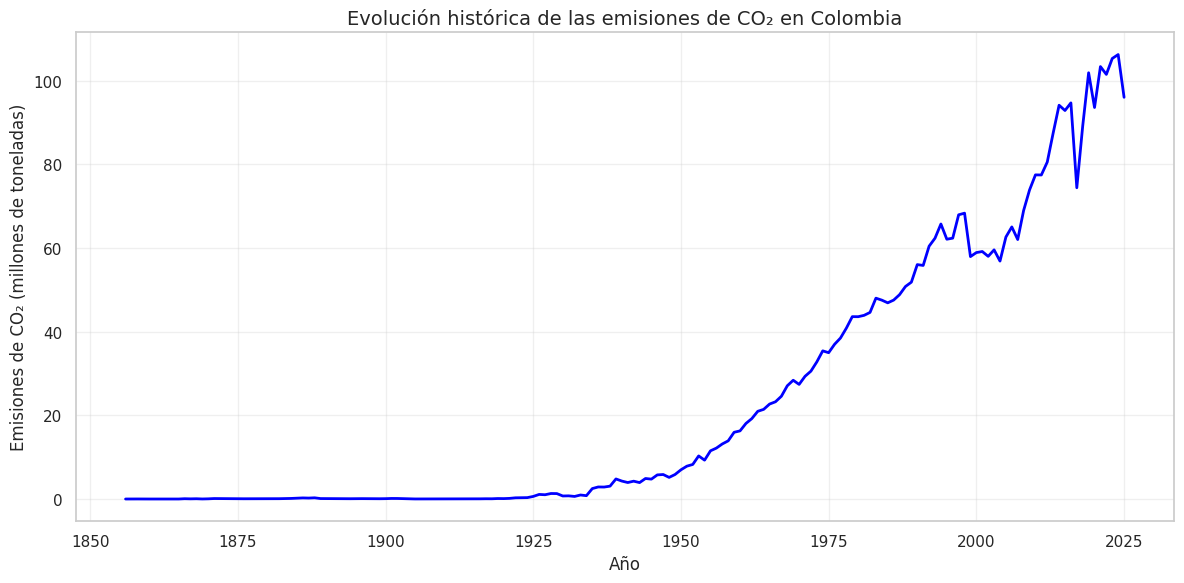

In [6]:
# PASO 7: Evolución histórica de las emisiones de CO2

plt.figure(figsize=(12, 6))

plt.plot(
    colombia_limpio["Year"],
    colombia_limpio["Annual CO₂ emissions"] / 1_000_000,
    color="blue",
    linewidth=2
)

plt.title(
    "Evolución histórica de las emisiones de CO₂ en Colombia",
    fontsize=14
)

plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (millones de toneladas)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Análisis del comportamiento de las emisiones de CO₂ en Colombia

Al observar la gráfica, se puede identificar que las emisiones de CO₂ en Colombia han aumentado considerablemente entre 1856 y 2025. Durante las primeras décadas, los niveles de contaminación registrados fueron bastante bajos y se mantuvieron sin grandes cambios. No obstante, desde mediados del siglo XX se empezó a presentar un incremento más notable.Entre 1950 y 2000, las emisiones crecieron de manera constante. A partir del año 2000, se pueden observar algunas subidas y bajadas, destacándose una caída importante alrededor de 2020. Después de este periodo, las emisiones volvieron a aumentar y alcanzaron valores superiores a los 100 millones de toneladas anuales.En los últimos años, aunque se han registrado algunos descensos, las emisiones continúan siendo mucho mayores en comparación con las de décadas anteriores.En general, los resultados muestran que las emisiones de CO₂ en Colombia han tenido un crecimiento importante a lo largo de su historia, lo que demuestra la necesidad de prestar atención a esta problemática ambiental y buscar alternativas que permitan disminuirlas.

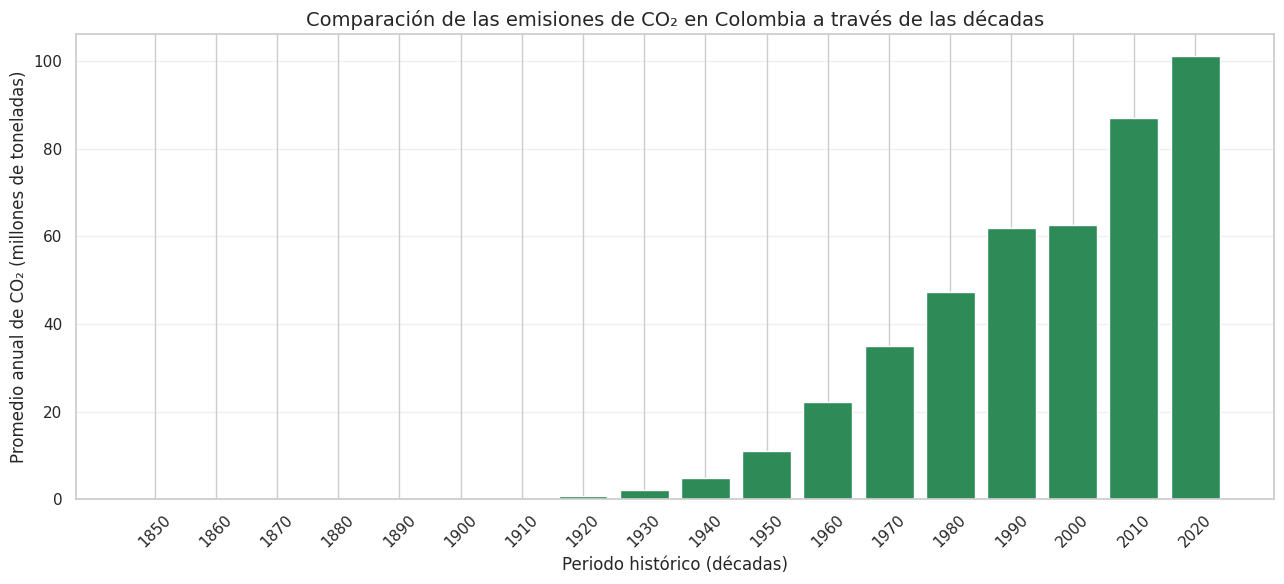

In [7]:

# PASO 9: Comparación de emisiones de CO2 por décadas

# Agrupar los años por décadas
colombia_limpio["Decada"] = (
    colombia_limpio["Year"] // 10
) * 10

# Calcular el promedio de emisiones por década
emisiones_decada = colombia_limpio.groupby(
    "Decada"
)["Annual CO₂ emissions"].mean() / 1_000_000

# Crear gráfica
plt.figure(figsize=(13, 6))

plt.bar(
    emisiones_decada.index.astype(str),
    emisiones_decada.values,
    color="seagreen"
)

plt.title(
    "Comparación de las emisiones de CO₂ en Colombia a través de las décadas",
    fontsize=14
)

plt.xlabel("Periodo histórico (décadas)")
plt.ylabel("Promedio anual de CO₂ (millones de toneladas)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Comparación de las emisiones de CO₂ por décadas

En esta parte del análisis se comparan las emisiones de dióxido de carbono registradas en Colombia durante diferentes décadas. Para ello, se calcula el promedio anual de emisiones de cada periodo y se representa mediante una gráfica de barras.Esta comparación permite observar cómo ha cambiado la cantidad de CO₂ emitida con el paso de los años e identificar los periodos en los que se presentaron los valores más altos.Es importante tener en cuenta que algunas décadas no cuentan con diez años completos de información, por lo que sus promedios se calculan únicamente con los registros disponibles

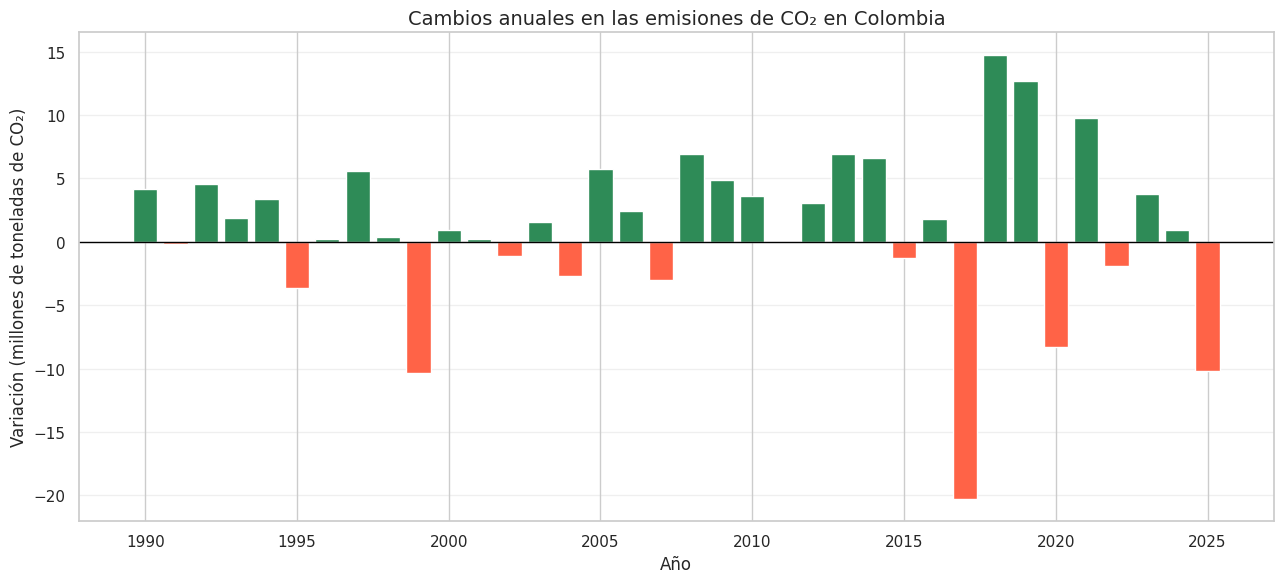

In [8]:

#  Variación anual de las emisiones de CO2

# Calcular el cambio de emisiones entre años consecutivos
colombia_limpio["Variacion_CO2"] = (
    colombia_limpio["Annual CO₂ emissions"].diff()
) / 1_000_000

# Seleccionar los datos desde 1990
datos_recientes = colombia_limpio[
    colombia_limpio["Year"] >= 1990
].copy()

# Asignar colores según el cambio
colores = [
    "seagreen" if valor >= 0 else "tomato"
    for valor in datos_recientes["Variacion_CO2"]
]

# Crear gráfica
plt.figure(figsize=(13, 6))

plt.bar(
    datos_recientes["Year"],
    datos_recientes["Variacion_CO2"],
    color=colores
)

plt.axhline(0, color="black", linewidth=1)

plt.title(
    "Cambios anuales en las emisiones de CO₂ en Colombia",
    fontsize=14
)

plt.xlabel("Año")
plt.ylabel("Variación (millones de toneladas de CO₂)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



*   Barras verdes: años en los que aumentaron las emisiones respecto al año   
    anterior.
*   Barras rojas: años en los que disminuyeron.
*   Línea horizontal: representa el punto donde no hubo variación.

Análisis de los cambios anuales en las emisiones de CO₂

Para complementar las gráficas anteriores, se realizó un análisis de las variaciones anuales de las emisiones de CO₂ en Colombia desde 1990. Para ello, se calculó la diferencia entre las emisiones de cada año y las del año anterior. Los resultados se representaron mediante una gráfica de barras, utilizando dos colores para diferenciar los aumentos y las disminuciones. Esto permite identificar los periodos en los que se presentaron los cambios más significativos.

In [9]:
# Modelo de regresión lineal

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Seleccionar datos desde 1990
datos_modelo = colombia_limpio[
    colombia_limpio["Year"] >= 1990
].copy()

# Variable independiente: año
X = datos_modelo[["Year"]]

# Variable dependiente: emisiones en millones de toneladas
y = datos_modelo["Annual CO₂ emissions"] / 1_000_000

# Separar datos cronológicamente
# Primer 80% para entrenamiento y último 20% para prueba
division = int(len(datos_modelo) * 0.8)

X_train = X.iloc[:division]
X_test = X.iloc[division:]

y_train = y.iloc[:division]
y_test = y.iloc[division:]

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Realizar predicciones
y_pred = modelo.predict(X_test)

# Evaluar el modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RESULTADOS DEL MODELO")
print("-------------------------")
print("Pendiente:", round(modelo.coef_[0], 4))
print("Intercepto:", round(modelo.intercept_, 4))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))


RESULTADOS DEL MODELO
-------------------------
Pendiente: 1.1447
Intercepto: -2224.6108
MAE: 10.3589
RMSE: 11.4728
R²: -3.0903


Aplicación del modelo de regresión lineal

Después de analizar las emisiones históricas de CO₂ en Colombia, se implementó un modelo de regresión lineal utilizando los registros comprendidos entre 1990 y 2025. Para su desarrollo, se tomó el año como variable independiente y la cantidad de emisiones como variable dependiente. Los datos se dividieron cronológicamente en un conjunto de entrenamiento del 80 % y otro de prueba del 20 %, con el propósito de evaluar el comportamiento del modelo frente a datos posteriores.Posteriormente, se realizó una gráfica para comparar las emisiones reales con la tendencia calculada mediante la regresión lineal, permitiendo identificar las diferencias entre los valores observados y las estimaciones del modelo.

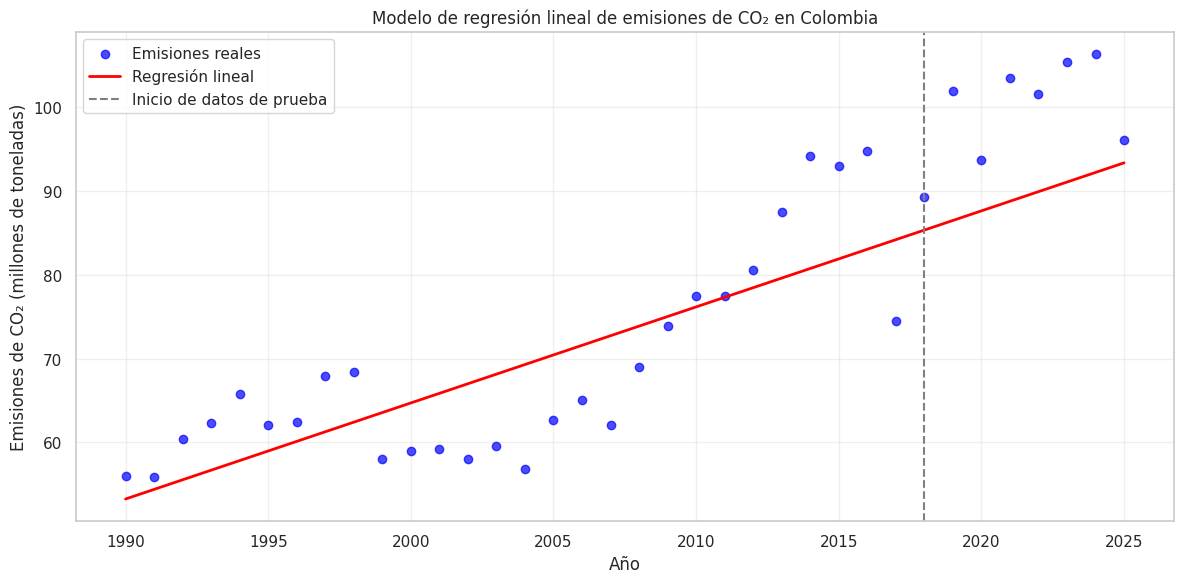

In [10]:

# Visualización de la regresión lineal

plt.figure(figsize=(12, 6))

# Emisiones reales
plt.scatter(
    X["Year"],
    y,
    color="blue",
    label="Emisiones reales",
    alpha=0.7
)

# Línea de regresión
plt.plot(
    X["Year"],
    modelo.predict(X),
    color="red",
    linewidth=2,
    label="Regresión lineal"
)

# Separación entre entrenamiento y prueba
plt.axvline(
    X_test["Year"].iloc[0],
    color="gray",
    linestyle="--",
    label="Inicio de datos de prueba"
)

plt.title("Modelo de regresión lineal de emisiones de CO₂ en Colombia")
plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (millones de toneladas)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Análisis de los resultados de la regresión lineal

La gráfica muestra la relación entre los años y las emisiones de CO₂ en Colombia durante el periodo de 1990 a 2025. Los puntos azules representan las emisiones registradas, mientras que la línea roja indica la tendencia calculada mediante el modelo de regresión lineal.Se observa que las emisiones presentan una tendencia creciente, con un aumento estimado de 1,14 millones de toneladas de CO₂ por año durante el periodo utilizado para entrenar el modelo. Sin embargo, los valores reales no siguen exactamente esta tendencia, especialmente en los años más recientes, donde se presentan diferencias importantes.Al evaluar el modelo, se obtuvo un R² de -3,09, lo que indica que su capacidad de predicción es limitada para los datos de prueba. Esto demuestra que, aunque la regresión lineal permite identificar una tendencia general, no logra representar adecuadamente todas las variaciones de las emisiones de CO₂ en Colombia.

**CONCLUSIONES**

---



A partir del análisis realizado, se identificó que las emisiones de CO₂ en Colombia han aumentado considerablemente desde 1856 hasta 2025, especialmente durante las últimas décadas. Aunque se presentan algunos periodos de disminución, la tendencia histórica general continúa siendo creciente.

Durante la preparación de los datos, se verificaron 170 registros correspondientes a Colombia y no fue necesario eliminar información, ya que los datos utilizados no presentaron valores faltantes ni inconsistencias que requirieran su eliminación.

Las visualizaciones permitieron comprender mejor el comportamiento de las emisiones, comparar diferentes décadas e identificar los años en los que se presentaron los cambios más significativos.

Finalmente, mediante la regresión lineal se identificó una tendencia de crecimiento en las emisiones. Sin embargo, los resultados de evaluación mostraron que el modelo tiene limitaciones para realizar predicciones precisas, debido a las variaciones que presentan los datos a lo largo del tiempo.

En general, este proyecto permitió aplicar herramientas de ciencia de datos para organizar, visualizar e interpretar información ambiental, demostrando la importancia del análisis de datos para comprender la evolución de las emisiones de CO₂ en Colombia.